# 04 · Sales (Olist): Exploratory Data Analysis

**Dataset:** Olist, a Brazilian online marketplace. ~99,000 real orders from 2016–2018.

**Our prediction goal:** when an order is approved, predict **whether it will be delivered late** (after the date promised to the customer).

**The big difference from the incident data:** sales is not one file but **9 linked files** (tables). Each describes one thing (orders, items, customers...), and they connect through ID columns, like a small database.
The EDA has two jobs: understand each table, and understand **how they connect**.

As before, we **don't change or save data here**. We only look and note what to fix.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW = ROOT / "data/raw/sales"
FIG = ROOT / "reports/figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 12,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")

## Step 1: Load all 9 tables
We store them in a **dictionary** (`tables["orders"]` gives the orders table), so we can loop over them easily.

In [2]:
files = {
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "translation": "product_category_name_translation.csv",
}
tables = {name: pd.read_csv(RAW / f) for name, f in files.items()}

overview = pd.DataFrame({
    name: {"rows": len(d), "columns": d.shape[1], "missing_cells": int(d.isna().sum().sum())}
    for name, d in tables.items()
}).T
overview

,rows,columns,missing_cells
orders,99441,8,4908
items,112650,7,0
payments,103886,5,0
reviews,99224,7,145903
customers,99441,5,0
sellers,3095,4,0
products,32951,9,2448
geolocation,1000163,5,0
translation,71,2,0


## Step 2: How the tables connect

```
                   customers (customer_id)
                        │
 payments ──┐           │
 reviews  ──┼── order_id ── ORDERS
 items    ──┘
   │  └── product_id ── products ── translation (category name)
   └───── seller_id  ── sellers

 customers.zip / sellers.zip ── geolocation (lat, lng)
```

| Table | One row = | Key | Joins to orders by |
|---|---|---|---|
| orders | one order | `order_id` | n/a |
| items | one item inside an order | `order_id` + `order_item_id` | `order_id` (many per order) |
| payments | one payment | `order_id` + `payment_sequential` | `order_id` (can be many) |
| reviews | one review | `review_id` | `order_id` (usually one) |
| customers | one customer **per order** | `customer_id` | `customer_id` |
| sellers | one seller | `seller_id` | via items |
| products | one product | `product_id` | via items |
| geolocation | one GPS point (many per zip code) | none! | via zip code |

**Why this matters:** if you join a table with *many rows per order* (like items) straight onto orders, each order gets **copied** once per item.
Your counts and averages become wrong without any error message. So we must **summarise those tables to one row per order first**.

Let's check which "keys" are really unique:

In [3]:
checks = {
    "orders.order_id": tables["orders"]["order_id"].is_unique,
    "customers.customer_id": tables["customers"]["customer_id"].is_unique,
    "sellers.seller_id": tables["sellers"]["seller_id"].is_unique,
    "products.product_id": tables["products"]["product_id"].is_unique,
    "reviews.order_id": tables["reviews"]["order_id"].is_unique,
    "reviews.review_id": tables["reviews"]["review_id"].is_unique,
    "payments.order_id": tables["payments"]["order_id"].is_unique,
    "items.order_id": tables["items"]["order_id"].is_unique,
    "geolocation.zip_code_prefix": tables["geolocation"]["geolocation_zip_code_prefix"].is_unique,
}
pd.Series(checks, name="is_unique").to_frame()

,is_unique
orders.order_id,True
customers.customer_id,True
sellers.seller_id,True
products.product_id,True
reviews.order_id,False
reviews.review_id,False
payments.order_id,False
items.order_id,False
geolocation.zip_code_prefix,False


➡ **To fix later:** reviews, payments, items and geolocation have several rows per key. Each must be reduced to one row per key before joining.

## Step 3: The orders table
This is the centre of everything. Let's look at it.

In [4]:
orders = tables["orders"].copy()
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


Missing values per column:

In [5]:
orders.isna().sum().to_frame("missing")

,missing
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


### Order status

In [6]:
orders["order_status"].value_counts().to_frame("orders")

,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


**What we learn:** 97% of orders are `delivered`. Only delivered orders have a real delivery date, so the late-delivery model can only learn from those.
The missing delivery dates are mostly the non-delivered orders, which is normal and not an error.

In [7]:
pd.crosstab(orders["order_status"], orders["order_delivered_customer_date"].isna(),
            colnames=["delivery date missing?"])

delivery date missing?,False,True
order_status,,
approved,0,2
canceled,6,619
created,0,5
delivered,96470,8
invoiced,0,314
processing,0,301
shipped,0,1107
unavailable,0,609


Note: 8 orders are `delivered` but have **no delivery date**. ➡ drop those from the model data.

### Dates
These dates are in a standard format (`2017-10-02 10:56:33`), so `pd.to_datetime` reads them without help.

In [8]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])
orders[date_cols].agg(["min", "max"]).T

,min,max
order_purchase_timestamp,2016-09-04 21:15:19,2018-10-17 17:30:18
order_approved_at,2016-09-15 12:16:38,2018-09-03 17:40:06
order_delivered_carrier_date,2016-10-08 10:34:01,2018-09-11 19:48:28
order_delivered_customer_date,2016-10-11 13:46:32,2018-10-17 13:22:46
order_estimated_delivery_date,2016-09-30 00:00:00,2018-11-12 00:00:00


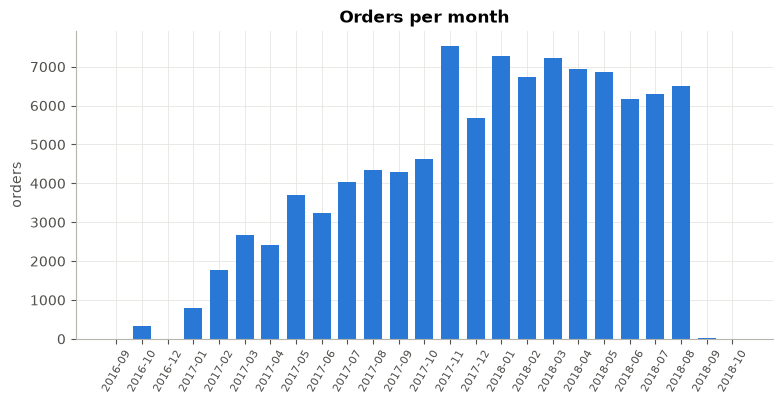

In [9]:
per_month = orders["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(per_month.index.astype(str), per_month.values, color=BLUE, width=0.7)
ax.set_title("Orders per month")
ax.set_ylabel("orders")
plt.xticks(rotation=60, fontsize=8)
save(fig, "sales_orders_per_month")
plt.show()

**What we learn:**
- 2016 has very few orders (the platform was just starting) and Sep–Oct 2018 has only a handful (the data export was cut off).
- Big spike in **November 2017** = Black Friday.

➡ **To fix later:** keep orders purchased **1 Jan 2017 – 31 Aug 2018**.

## Step 4: The target: late deliveries
`late = delivered to customer AFTER the estimated (promised) delivery date`

In [10]:
d = orders[(orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].notna()].copy()
d["late"] = d["order_delivered_customer_date"] > d["order_estimated_delivery_date"]
print(f"Delivered orders: {len(d):,}")
print(f"Late: {d['late'].sum():,}  ({d['late'].mean():.1%})")

Delivered orders: 96,470
Late: 7,826  (8.1%)


Only **~8% are late**. This is an **imbalanced** target: a model that always says "on time" would be 92% "accurate" yet useless.
So we'll judge models with **AUC** (how well they *rank* risky orders above safe ones), not accuracy.

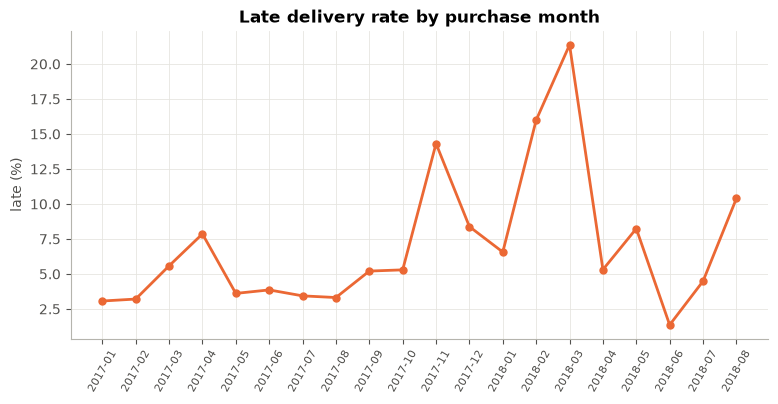

In [11]:
monthly_late = d[(d["order_purchase_timestamp"] >= "2017-01-01") & (d["order_purchase_timestamp"] < "2018-09-01")]
monthly_late = monthly_late.groupby(monthly_late["order_purchase_timestamp"].dt.to_period("M"))["late"].mean() * 100
fig, ax = plt.subplots()
ax.plot(monthly_late.index.astype(str), monthly_late.values, color=ORANGE, linewidth=2, marker="o", markersize=5)
ax.set_title("Late delivery rate by purchase month")
ax.set_ylabel("late (%)")
plt.xticks(rotation=60, fontsize=8)
save(fig, "sales_late_rate_by_month")
plt.show()

**Drift again:** late rates jump in **Nov 2017** (Black Friday) and **Feb–Mar 2018** (likely carrier problems / strikes), then drop.
"How are deliveries going *recently*" will be a useful feature.

### How many days does delivery take, and how many were promised?

In [12]:
d["delivery_days"] = (d["order_delivered_customer_date"] - d["order_purchase_timestamp"]).dt.total_seconds() / 86400
d["promised_days"] = (d["order_estimated_delivery_date"] - d["order_purchase_timestamp"]).dt.total_seconds() / 86400
d[["delivery_days", "promised_days"]].describe(percentiles=[.1, .5, .9, .99]).round(1)

,delivery_days,promised_days
count,96470.0,96470.0
mean,12.6,23.7
std,9.5,8.8
min,0.5,2.0
10%,4.2,13.1
50%,10.2,23.2
90%,23.1,34.3
99%,46.1,50.2
max,209.6,155.1


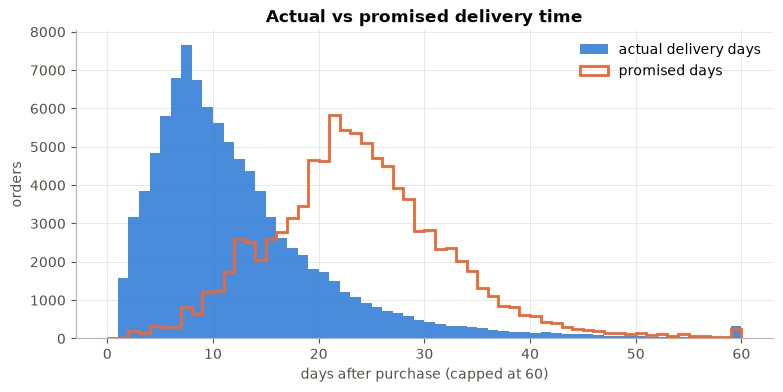

In [13]:
fig, ax = plt.subplots()
bins = np.arange(0, 61, 1)
ax.hist(d["delivery_days"].clip(upper=60), bins=bins, color=BLUE, alpha=0.85, label="actual delivery days")
ax.hist(d["promised_days"].clip(upper=60), bins=bins, histtype="step", color=ORANGE, linewidth=2, label="promised days")
ax.set_title("Actual vs promised delivery time")
ax.set_xlabel("days after purchase (capped at 60)")
ax.set_ylabel("orders")
ax.legend(frameon=False)
save(fig, "sales_delivery_vs_promised")
plt.show()

**What we learn:** Olist usually promises ~23 days while delivery takes ~10. Most orders arrive early.
Orders with a **short promise** are the ones at risk, so "promised days" will be an important feature.

## Step 5: Timeline sanity checks
Logical order should be: purchase → approved → handed to carrier → delivered to customer.

In [14]:
sanity = {
    "approved before purchase": (d["order_approved_at"] < d["order_purchase_timestamp"]).sum(),
    "carrier pickup before purchase": (d["order_delivered_carrier_date"] < d["order_purchase_timestamp"]).sum(),
    "carrier pickup before approval": (d["order_delivered_carrier_date"] < d["order_approved_at"]).sum(),
    "delivered before carrier pickup": (d["order_delivered_customer_date"] < d["order_delivered_carrier_date"]).sum(),
    "approval date missing": d["order_approved_at"].isna().sum(),
}
pd.Series(sanity, name="orders").to_frame()

,orders
approved before purchase,0
carrier pickup before purchase,165
carrier pickup before approval,1350
delivered before carrier pickup,23
approval date missing,14


**What we learn:**
- Pickup **before purchase** or delivery **before pickup** is impossible → drop those (~190 orders).
- Pickup a little before *approval* happens ~1,350 times. Usually it's the same day, a clock/recording difference. We keep these orders but treat negative "dispatch time" as 0.
- A few approval dates are missing → fill with the purchase time.

## Step 6: Customers: `customer_id` is NOT the person

In [15]:
cust = tables["customers"]
print(f"customer_id values       : {cust['customer_id'].nunique():,}")
print(f"customer_unique_id values: {cust['customer_unique_id'].nunique():,}")
print(f"People with 2+ orders    : {(cust['customer_unique_id'].value_counts() > 1).sum():,}")

customer_id values       : 99,441
customer_unique_id values: 96,096
People with 2+ orders    : 2,997


Olist creates a new `customer_id` for **every order**. The real person is `customer_unique_id`. ➡ Use it to find repeat customers.

## Step 7: Items: what's inside each order

In [16]:
items = tables["items"]
per_order = items.groupby("order_id").agg(n_items=("order_item_id", "size"), n_sellers=("seller_id", "nunique"))
print(per_order["n_items"].value_counts().head(6).to_string())
print(f"\nOrders with more than one seller: {(per_order['n_sellers'] > 1).sum():,} of {len(per_order):,}")
print(f"Orders with NO items at all:      {(~orders['order_id'].isin(items['order_id'])).sum():,}")
items[["price", "freight_value"]].describe(percentiles=[.5, .9, .99]).round(2)

n_items
1    88863
2     7516
3     1322
4      505
5      204
6      198

Orders with more than one seller: 1,278 of 98,666
Orders with NO items at all:      775


,price,freight_value
count,112650.00,112650.00
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
50%,74.99,16.26
90%,229.80,34.04
99%,890.00,84.52
max,6735.00,409.68


**What we learn:** most orders have 1 item from 1 seller. ~1,300 orders have several sellers. We'll pick a **main seller** (the one with the highest value in the order).
Prices are right-skewed (a few very expensive items).

## Step 8: Payments

In [17]:
pay = tables["payments"]
print(pay["payment_type"].value_counts().to_string())
print("\nPayments per order:\n", pay.groupby("order_id").size().value_counts().head().to_string())

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3

Payments per order:
 1    96479
2     2382
3      301
4      108
5       52


`boleto` is a Brazilian bank slip, paid in cash later. It delays approval. `not_defined` appears 3 times (treat as missing).
Some orders are paid in parts (e.g. voucher + card) ➡ summarise per order: total value, number of payments, main type.

## Step 9: Reviews, and why late delivery matters to the business

In [18]:
rev = tables["reviews"]
print("Orders with more than one review:", (rev["order_id"].value_counts() > 1).sum())
print(rev["review_score"].value_counts().sort_index().to_string())

Orders with more than one review: 547
review_score
1    11424
2     3151
3     8179
4    19142
5    57328


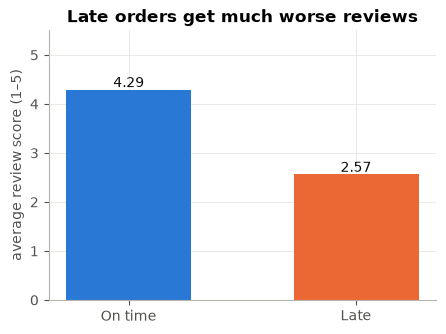

In [19]:
one_review = rev.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")
dr = d.merge(one_review[["order_id", "review_score"]], on="order_id", how="left")
score = dr.groupby("late")["review_score"].mean()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["On time", "Late"], score.values, color=[BLUE, ORANGE], width=0.55)
for i, v in enumerate(score.values):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center", color="#0b0b0b")
ax.set_ylim(0, 5.5)
ax.set_ylabel("average review score (1–5)")
ax.set_title("Late orders get much worse reviews")
save(fig, "sales_review_by_late")
plt.show()

**This is your business-impact chart:** late orders score ~2.3 stars vs ~4.3 on time. Predicting and preventing late deliveries directly protects customer satisfaction.

⚠ **Leakage note:** the review is written *after* delivery. It can never be a feature, only a way to show impact.

## Step 10: Products

In [20]:
prod = tables["products"]
print(prod.isna().sum().to_string())
trans = tables["translation"]
untranslated = set(prod["product_category_name"].dropna()) - set(trans["product_category_name"])
print("\nCategories with no English translation:", untranslated)

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2

Categories with no English translation: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


➡ **To fix later:** 610 products have no category (→ `"unknown"`); 2 categories lack a translation (→ add them by hand); 2 products miss size/weight (→ fill with the category median).
Also note the column names are misspelled in the original data (`product_name_lenght`). We'll rename them.

## Step 11: Geolocation: turning zip codes into map coordinates
We want the **distance** between seller and customer. Geolocation gives latitude/longitude per zip code prefix, but with **many points per zip** and some errors.

In [21]:
geo = tables["geolocation"]
print(f"Rows: {len(geo):,}   Distinct zip prefixes: {geo['geolocation_zip_code_prefix'].nunique():,}")
outside = ~(geo["geolocation_lat"].between(-34, 5.5) & geo["geolocation_lng"].between(-74, -34))
print(f"Points outside Brazil (errors): {outside.sum()}")
zips = set(geo["geolocation_zip_code_prefix"])
print(f"Customer zips with no coordinates: {(~cust['customer_zip_code_prefix'].isin(zips)).sum()}")
print(f"Seller zips with no coordinates:   {(~tables['sellers']['seller_zip_code_prefix'].isin(zips)).sum()}")

Rows: 1,000,163   Distinct zip prefixes: 19,015
Points outside Brazil (errors): 42
Customer zips with no coordinates: 278
Seller zips with no coordinates:   7


➡ **To fix later:** remove points outside Brazil, then take the **median** lat/lng per zip (one row per zip). A few zips will have no location; the distance will just be missing for those orders.

## Step 12: Where are late deliveries most common?

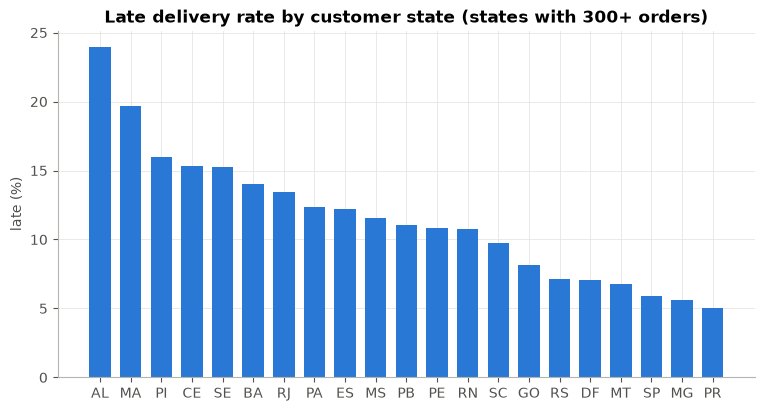

,orders,late_rate
customer_state,,
AL,397,0.239
MA,717,0.197
PI,476,0.160
CE,1279,0.153
SE,335,0.152
BA,3256,0.140
RJ,12350,0.135
TO,274,0.128
PA,946,0.124


In [22]:
dc = d.merge(cust[["customer_id", "customer_state"]], on="customer_id", how="left")
by_state = dc.groupby("customer_state")["late"].agg(orders="size", late_rate="mean").sort_values("late_rate", ascending=False)
top = by_state[by_state["orders"] >= 300]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(top.index, top["late_rate"] * 100, color=BLUE, width=0.7)
ax.set_title("Late delivery rate by customer state (states with 300+ orders)")
ax.set_ylabel("late (%)")
save(fig, "sales_late_by_state")
plt.show()
by_state.round(3).head(10)

Remote north-eastern states (AL, MA, SE, CE...) are late far more often than São Paulo (SP), where most sellers are. ➡ Geography and distance matter.

## Step 13: Summary: what we learned and what to fix

| # | Finding | What we'll do (notebook 05 / 06) |
|---|---|---|
| 1 | 9 linked tables; some have many rows per order | Summarise items, payments, reviews, geolocation to one row per key **before** joining |
| 2 | Dates are text | `pd.to_datetime` |
| 3 | Only delivered orders have a delivery date | Model data = delivered orders with a delivery date |
| 4 | Thin data in 2016 and Sep–Oct 2018 | Keep purchases 1 Jan 2017 – 31 Aug 2018 |
| 5 | ~190 impossible timelines | Drop them; negative dispatch time → 0; missing approval → purchase time |
| 6 | `customer_id` ≠ person | Use `customer_unique_id` for repeat customers |
| 7 | Multi-seller orders | Choose a main seller (highest value) |
| 8 | Product category missing / untranslated, misspelt columns | Fill `"unknown"`, translate, rename |
| 9 | Geolocation has many points per zip and some errors | Filter to Brazil, median per zip |
| 10 | Late target is imbalanced (~8%) | Evaluate with AUC, not accuracy |
| 11 | Late rate drifts over time | Add "recent" late-rate features |
| 12 | Reviews and delivery dates are only known after the fact | Never use as features (leakage) |

➡ Next: **05_sales_cleaning.ipynb**